<a href="https://colab.research.google.com/github/muralisagili007-del/EDA-PROJECT/blob/main/LR(OCT).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Import  liabraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

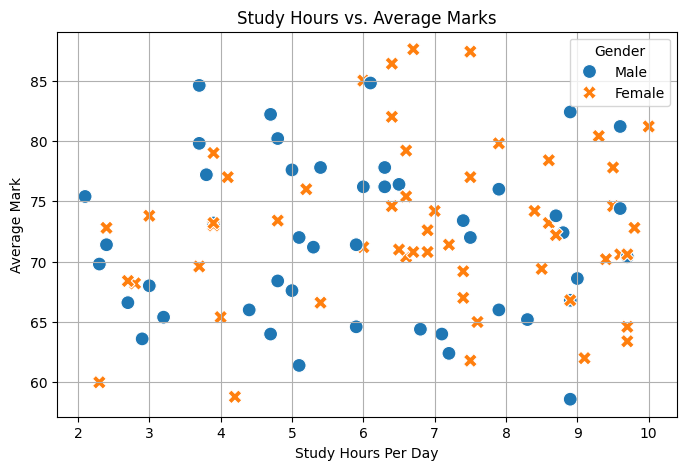

Correlation between Study Hours and Average Mark: 0.05


In [8]:
# Calculate 'Exam_Marks' as the average of the subject columns if not already present
subject_cols = ['Math', 'Physics', 'Chemistry', 'English', 'Biology']
df['Exam_Marks'] = df[subject_cols].mean(axis=1)

plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='Study_Hours_Per_Day', y='Exam_Marks', hue='Gender', style='Gender', s=100)
plt.title('Study Hours vs. Average Marks')
plt.xlabel('Study Hours Per Day')
plt.ylabel('Average Mark')
plt.grid(True)
plt.show()

# Calculate correlation
correlation = df['Study_Hours_Per_Day'].corr(df['Exam_Marks'])
print(f"Correlation between Study Hours and Average Mark: {correlation:.2f}")

In [6]:
df = pd.read_csv("student_marks.csv")

In [ ]:
df.head()

,Student_ID,Gender,Study_Hours_Per_Day,Math,Physics,Chemistry,English,Biology
0,STU_001,Male,2.1,83,63,67,85,79
1,STU_002,Female,9.5,96,65,67,68,93
2,STU_003,Female,6.0,73,64,83,75,61
3,STU_004,Male,6.3,59,99,83,52,88
4,STU_005,Female,7.5,87,99,59,68,72


In [ ]:
df.tail()

,Student_ID,Gender,Study_Hours_Per_Day,Math,Physics,Chemistry,English,Biology
95,STU_096,Male,9.0,60,81,68,82,52
96,STU_097,Female,3.9,89,84,42,54,97
97,STU_098,Female,9.3,62,96,59,97,88
98,STU_099,Female,6.7,91,92,99,68,88
99,STU_100,Male,4.8,97,45,98,53,49


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Student_ID           100 non-null    object 
 1   Gender               100 non-null    object 
 2   Study_Hours_Per_Day  100 non-null    float64
 3   Math                 100 non-null    int64  
 4   Physics              100 non-null    int64  
 5   Chemistry            100 non-null    int64  
 6   English              100 non-null    int64  
 7   Biology              100 non-null    int64  
 8   Exam_Marks           100 non-null    float64
dtypes: float64(2), int64(5), object(2)
memory usage: 7.2+ KB


In [ ]:
df.duplicated().sum()

np.int64(0)

In [10]:
df.drop_duplicates(inplace=True)

In [11]:
df.isnull().sum()

,0
Student_ID,0
Gender,0
Study_Hours_Per_Day,0
Math,0
Physics,0
Chemistry,0
English,0
Biology,0
Exam_Marks,0


In [12]:
# Calculate 'Exam_Marks' as the average of all subject columns
subject_cols = ['Math', 'Physics', 'Chemistry', 'English', 'Biology']
df['Exam_Marks'] = df[subject_cols].mean(axis=1)

In [13]:
# Calculate 'Exam_Marks' as the average of all five subjects
subject_cols = ['Math', 'Physics', 'Chemistry', 'English', 'Biology']
df['Exam_Marks'] = df[subject_cols].mean(axis=1)

# Display the updated DataFrame to verify the new column
display(df.head())

,Student_ID,Gender,Study_Hours_Per_Day,Math,Physics,Chemistry,English,Biology,Exam_Marks
0,STU_001,Male,2.1,83,63,67,85,79,75.4
1,STU_002,Female,9.5,96,65,67,68,93,77.8
2,STU_003,Female,6.0,73,64,83,75,61,71.2
3,STU_004,Male,6.3,59,99,83,52,88,76.2
4,STU_005,Female,7.5,87,99,59,68,72,77.0


In [14]:
df['Study_Hours_Per_Day'] = df['Study_Hours_Per_Day'].fillna(df['Study_Hours_Per_Day'].mean())

In [15]:
df.isnull().sum()

,0
Student_ID,0
Gender,0
Study_Hours_Per_Day,0
Math,0
Physics,0
Chemistry,0
English,0
Biology,0
Exam_Marks,0


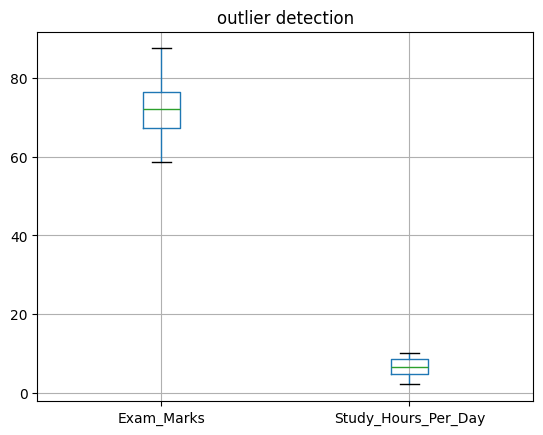

In [16]:
#outlier treatment
df.boxplot(column=['Exam_Marks', 'Study_Hours_Per_Day'])
plt.title("outlier detection")
plt.show()

In [17]:
#outlier treatment
for col in ['Exam_Marks', 'Study_Hours_Per_Day']:
  Q1 = df[col].quantile(0.25)
  Q3 = df[col].quantile(0.75)
  IQR = Q3 - Q1

  lower = Q1 - 1.5 * IQR
  upper = Q3 + 1.5 * IQR

  # Cap outliers to the lower and upper bounds
  df[col] = np.clip(df[col], lower, upper)

print("Outliers successfully capped using the IQR method!")

Outliers successfully capped using the IQR method!


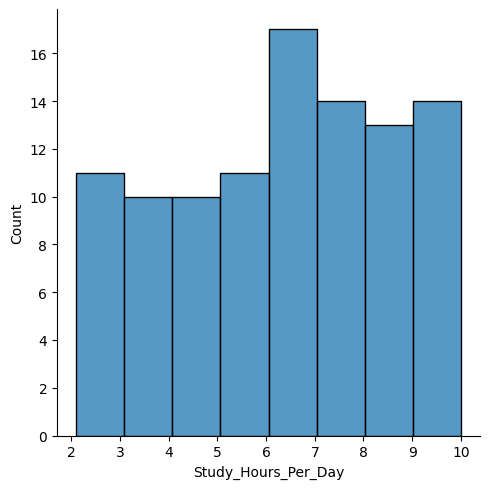

In [18]:
#univarite analysis
sns.displot(df['Study_Hours_Per_Day'])
plt.show()

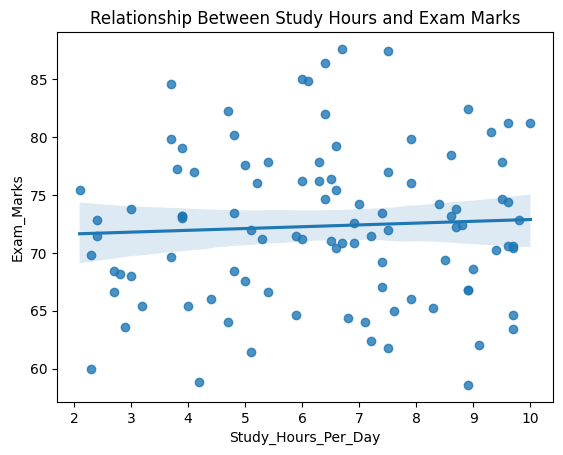

In [19]:
# Bivariate Analysis
sns.regplot(x=df['Study_Hours_Per_Day'], y=df['Exam_Marks'])
plt.title('Relationship Between Study Hours and Exam Marks')
plt.show()

In [ ]:
from google.colab import files
uploaded=files.upload()

Saving student_marks.csv to student_marks (1).csv


In [20]:
import pandas as pd

# Reload the dataset to ensure 'df' is defined
df = pd.read_csv('student_marks.csv')

# Re-calculate 'Exam_Marks' as the average of the subject columns
subject_cols = ['Math', 'Physics', 'Chemistry', 'English', 'Biology']
df['Exam_Marks'] = df[subject_cols].mean(axis=1)

# Separate X and y
# We drop 'Exam_Marks' as the target, and 'Student_ID'/'Gender' since they are non-numeric identifiers/categorical
X = df.drop(['Exam_Marks', 'Student_ID', 'Gender'], axis=1)
y = df['Exam_Marks']

print("Features (X) columns:", X.columns.tolist())
print("Target (y) shape:", y.shape)

Features (X) columns: ['Study_Hours_Per_Day', 'Math', 'Physics', 'Chemistry', 'English', 'Biology']
Target (y) shape: (100,)


In [ ]:
from google.colab import files
df = files.upload()

In [ ]:
# Reload the dataset to fix the overridden 'df' dictionary variable
df = pd.read_csv('student_marks.csv')

# Re-calculate 'Exam_Marks' as the average of the subject columns
subject_cols = ['Math', 'Physics', 'Chemistry', 'English', 'Biology']
df['Exam_Marks'] = df[subject_cols].mean(axis=1)

# Safely extract target variable y
y = df['Exam_Marks']

In [21]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [22]:
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

In [23]:
# Predict using the full test set since the model was trained on all 6 features
y_pred = model.predict(X_test)

In [24]:
print(y_pred)

[72.2 77.8 69.6 75.4 65.4 77.8 67.6 65.  74.2 75.4 62.4 77.  63.6 80.2
 65.4 77.  81.2 72.8 70.4 76.2]


In [25]:
results = pd.DataFrame({'Actual':y_test,   'predicted': y_pred})
print(results)

    Actual  predicted
83    72.2       72.2
53    77.8       77.8
70    69.6       69.6
45    75.4       75.4
44    65.4       65.4
39    77.8       77.8
22    67.6       67.6
80    65.0       65.0
10    74.2       74.2
0     75.4       75.4
18    62.4       62.4
30    77.0       77.0
73    63.6       63.6
33    80.2       80.2
90    65.4       65.4
4     77.0       77.0
76    81.2       81.2
77    72.8       72.8
12    70.4       70.4
31    76.2       76.2


In [ ]:
from sklearn.metrics import mean_squared_error, r2_score

mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("mean Squared Error:", mse)
print("R-squared Score:", r2)

mean Squared Error: 1.413638742156053e-28
R-squared Score: 1.0


In [26]:
# We must define all 6 features that the model was trained on
new_student = pd.DataFrame({
    'Study_Hours_Per_Day': [6],
    'Math': [80],
    'Physics': [75],
    'Chemistry': [70],
    'English': [85],
    'Biology': [80]
})

# Predict using the correctly spelled DataFrame variable
predicted_exam_marks = model.predict(new_student)
print("Predicted Exam Marks:", predicted_exam_marks[0])

Predicted Exam Marks: 78.0


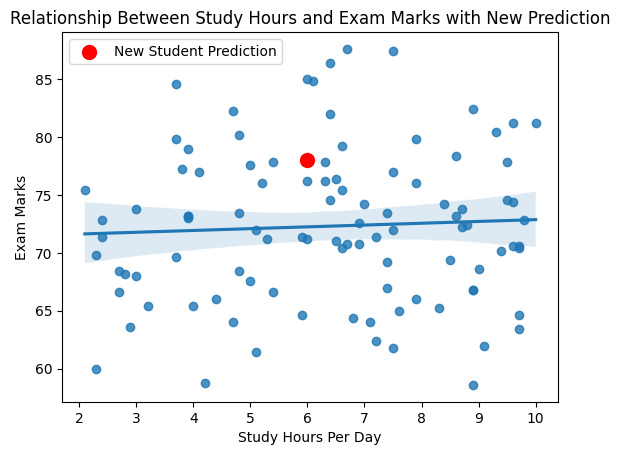

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Load the dataset from the CSV file
df_plot = pd.read_csv('student_marks.csv')

# Calculate average exam marks
subject_cols = ['Math', 'Physics', 'Chemistry', 'English', 'Biology']
df_plot['Exam_Marks'] = df_plot[subject_cols].mean(axis=1)

# Plot the regression line using df_plot
sns.regplot(x=df_plot['Study_Hours_Per_Day'], y=df_plot['Exam_Marks'])

# Overlay the prediction for our new student
plt.scatter(new_student['Study_Hours_Per_Day'], predicted_exam_marks, color='red', marker='o', s=100, label='New Student Prediction')

plt.title('Relationship Between Study Hours and Exam Marks with New Prediction')
plt.xlabel('Study Hours Per Day')
plt.ylabel('Exam Marks')
plt.legend()
plt.show()